# 03. 데이터 개요와 구매 구조

상품라인·고객·할인·마케팅·세금 데이터의 구성과 분석 단위를 확인한다. 이어 월별 고객 주문·상품매출, 고객별 주문·구매일, RFM 입력 지표와 등급 분포를 살펴본다.


In [1]:
import json
import io
import contextlib
from pathlib import Path
import pandas as pd
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots

root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p/'notebooks'/'02_data_preparation.ipynb').exists())
prep_path = root/'notebooks'/'02_data_preparation.ipynb'
prep = json.loads(prep_path.read_text(encoding='utf-8'))
for cell in prep['cells']:
    if cell['cell_type']=='code' and 'pipeline' in cell.get('metadata',{}).get('tags',[]):
        with contextlib.redirect_stdout(io.StringIO()):
            exec(compile(''.join(cell['source']),str(prep_path),'exec'),globals())
print('분석 테이블 준비 완료')


분석 테이블 준비 완료


## 1. 입력 파일과 분석 단위

다섯 CSV를 상품라인 기준으로 결합했다. 상품라인, <strong>고객 주문 <code>(고객ID, 거래ID)</code></strong>, 고객의 세 단위를 구분한다.


In [2]:
source_catalog=pd.DataFrame([
    ['Onlinesales_info.csv','상품라인',len(sales),', '.join(sales.columns)],
    ['Customer_info.csv','고객',len(customer),', '.join(customer.columns)],
    ['Discount_info.csv','월 × 제품카테고리',len(discount),', '.join(discount.columns)],
    ['Marketing_info.csv','날짜',len(marketing),', '.join(marketing.columns)],
    ['Tax_info.csv','제품카테고리',len(tax),', '.join(tax.columns)],
],columns=['파일','단위','행','컬럼'])
table_catalog=pd.DataFrame([
    ['sales_lines','상품라인',len(sales_lines)],
    ['analysis_orders','고객ID × 거래ID',len(analysis_orders)],
    ['analysis_customers','고객ID',len(analysis_customers)],
],columns=['분석 테이블','단위','행'])
print('입력 파일')
display(source_catalog)
print()
print('분석 테이블')
display(table_catalog)


입력 파일


,파일,단위,행,컬럼
0,Onlinesales_info.csv,상품라인,52924,"고객ID, 거래ID, 거래날짜, 제품ID, 제품카테고리, 수량, 평균금액, 배송료,..."
1,Customer_info.csv,고객,1468,"고객ID, 성별, 고객지역, 가입기간"
2,Discount_info.csv,월 × 제품카테고리,204,"월, 제품카테고리, 쿠폰코드, 할인율"
3,Marketing_info.csv,날짜,365,"날짜, 오프라인비용, 온라인비용"
4,Tax_info.csv,제품카테고리,20,"제품카테고리, GST"



분석 테이블


,분석 테이블,단위,행
0,sales_lines,상품라인,52924
1,analysis_orders,고객ID × 거래ID,26631
2,analysis_customers,고객ID,1468


## 2. 주요 분석 컬럼

컬럼명과 자료형을 확인한다. `세후금액`은 상품라인 매출, `상품매출`은 고객 주문 매출이다. 배송비는 `고객결제액`에만 더한다. 고객 테이블에는 주문 빈도와 구매일 수를 따로 보관한다.


In [3]:
for name,frame in [
    ('sales_lines',sales_lines),
    ('analysis_orders',analysis_orders),
    ('analysis_customers',analysis_customers),
]:
    schema=pd.DataFrame({
        '컬럼':frame.columns,
        '자료형':[str(x) for x in frame.dtypes],
        '결측 수':frame.isna().sum().to_numpy()
    })
    print(f'[{name}]')
    display(schema)
    print()


[sales_lines]


,컬럼,자료형,결측 수
0,고객ID,object,0
1,거래ID,object,0
2,거래날짜,datetime64[ns],0
3,제품ID,object,0
4,제품카테고리,object,0
5,수량,int64,0
6,평균금액,float64,0
7,배송료,float64,0
8,쿠폰상태,object,0
9,연도,int32,0



[analysis_orders]


,컬럼,자료형,결측 수
0,고객ID,object,0
1,거래ID,object,0
2,거래날짜,datetime64[ns],0
3,상품매출,float64,0
4,배송비,float64,0
5,상품라인수,int64,0
6,고객결제액,float64,0



[analysis_customers]


,컬럼,자료형,결측 수
0,고객ID,object,0
1,Recency,int64,0
2,Frequency,int64,0
3,Monetary,float64,0
4,R,int64,0
5,F,int64,0
6,M,int64,0
7,RFM_score,float64,0
8,등급,object,0
9,세그먼트,object,0


### 분석 테이블의 처음 5행

상품라인의 할인·세금·배송비 계산 결과, 고객 주문의 합계, 고객별 구매 이력이 각각 어떤 형태인지 확인한다.


In [4]:
preview_columns = [
    ('상품라인', sales_lines,
     ['고객ID','거래ID','거래날짜','제품카테고리','쿠폰상태','할인적용여부',
      'gst','세후금액','배송비_배부액','최종결제금액']),
    ('고객 주문', analysis_orders,
     ['고객ID','거래ID','거래날짜','상품라인수','상품매출','배송비','고객결제액']),
    ('고객', analysis_customers,
     ['고객ID','첫구매일','마지막구매일','구매일수','Recency','Frequency',
      'Monetary','등급','세그먼트']),
]
for name, frame, columns in preview_columns:
    print(f'[{name}] {len(frame):,}행')
    display(frame[columns].head(5))


[상품라인] 52,924행


,고객ID,거래ID,거래날짜,제품카테고리,쿠폰상태,할인적용여부,gst,세후금액,배송비_배부액,최종결제금액
0,USER_1358,Transaction_0000,2019-01-01,Nest-USA,Used,1,0.10,152.17,6.5,158.67
1,USER_1358,Transaction_0001,2019-01-01,Nest-USA,Used,1,0.10,152.17,6.5,158.67
2,USER_1358,Transaction_0002,2019-01-01,Office,Used,1,0.10,2.02,6.5,8.52
3,USER_1358,Transaction_0003,2019-01-01,Apparel,Not Used,0,0.18,103.43,6.5,109.93
4,USER_1358,Transaction_0003,2019-01-01,Bags,Used,1,0.18,17.52,0.0,17.52


[고객 주문] 26,631행


,고객ID,거래ID,거래날짜,상품라인수,상품매출,배송비,고객결제액
0,USER_0000,Transaction_16900,2019-09-15,2,24.98,75.00,99.98
1,USER_0001,Transaction_20178,2019-11-01,2,12.47,20.85,33.32
2,USER_0001,Transaction_20179,2019-11-01,2,21.66,6.00,27.66
3,USER_0001,Transaction_20180,2019-11-02,1,163.90,6.00,169.90
4,USER_0001,Transaction_20181,2019-11-02,1,163.90,6.00,169.90


[고객] 1,468행


,고객ID,첫구매일,마지막구매일,구매일수,Recency,Frequency,Monetary,등급,세그먼트
0,USER_0000,2019-09-15,2019-09-15,1,107,1,24.98,Bronze,최근·저빈도 고객
1,USER_0001,2019-03-24,2019-11-02,3,59,31,15021.66,Platinum,VIP 고객
2,USER_0002,2019-06-22,2019-10-19,2,73,8,1492.41,Bronze,최근·저빈도 고객
3,USER_0003,2019-12-14,2019-12-14,1,17,11,1339.57,Silver,가망 고객
4,USER_0004,2019-09-15,2019-09-15,1,107,13,1369.94,Silver,휴면 고객


## 3. 결합 필드와 주문 구성

전처리에 사용한 제품카테고리·GST, 고객 속성, 쿠폰 상태, 마케팅 비용과 배송비의 규모를 차트로 확인한다. 이 구성만으로 할인이나 마케팅의 효과를 판단하지 않는다.


### 제품카테고리·GST와 고객 속성


In [5]:
category_profile = (sales_lines.groupby('제품카테고리', as_index=False)
    .agg(상품라인수=('제품ID','size'),GST=('gst','first'))
    .sort_values('상품라인수',ascending=False))
gender_counts = customer['성별'].value_counts(dropna=False)
region_counts = customer['고객지역'].value_counts(dropna=False)
assert len(category_profile)==tax['제품카테고리'].nunique()
assert category_profile['상품라인수'].sum()==len(sales_lines)


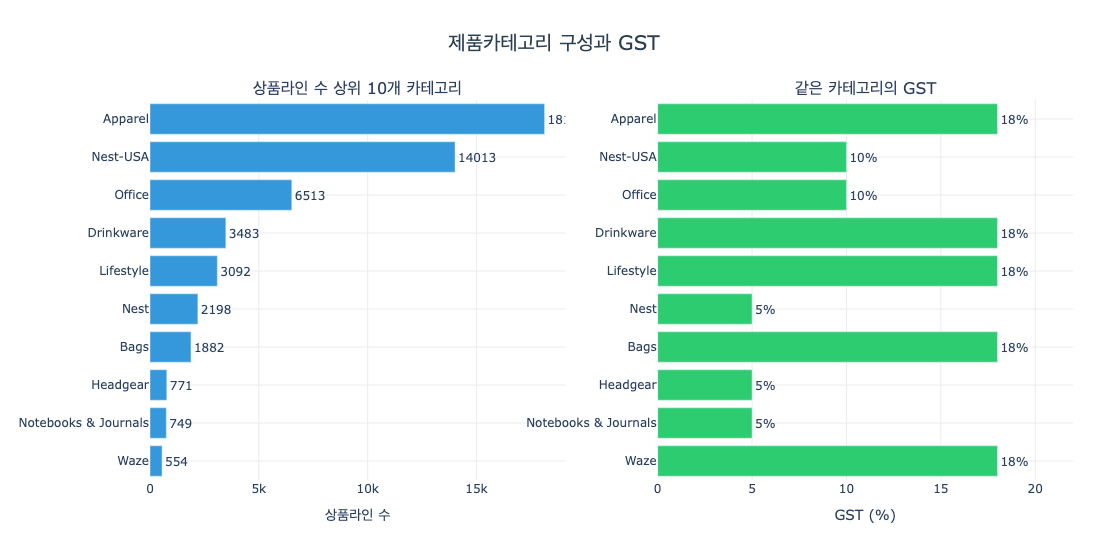

In [6]:
top_categories = category_profile.head(10).sort_values('상품라인수')
fig = make_subplots(rows=1,cols=2,
    subplot_titles=['상품라인 수 상위 10개 카테고리','같은 카테고리의 GST'])
fig.add_trace(go.Bar(x=top_categories['상품라인수'],y=top_categories['제품카테고리'],
    orientation='h',marker_color='#3498db',showlegend=False,
    text=top_categories['상품라인수'],textposition='outside'),row=1,col=1)
fig.add_trace(go.Bar(x=top_categories['GST']*100,y=top_categories['제품카테고리'],
    orientation='h',marker_color='#2ecc71',showlegend=False,
    text=[f'{v:.0f}%' for v in top_categories['GST']*100],textposition='outside'),row=1,col=2)
fig.update_layout(title=dict(text='제품카테고리 구성과 GST',x=0.5,xanchor='center',
    font=dict(size=20,color='#2c3e50')),height=560,plot_bgcolor='white',
    margin=dict(l=150,r=35))
fig.update_xaxes(gridcolor='#ececec')
fig.update_xaxes(title_text='상품라인 수',row=1,col=1)
fig.update_xaxes(title_text='GST (%)',range=[0,22],row=1,col=2)
fig.update_yaxes(gridcolor='#ececec')
fig


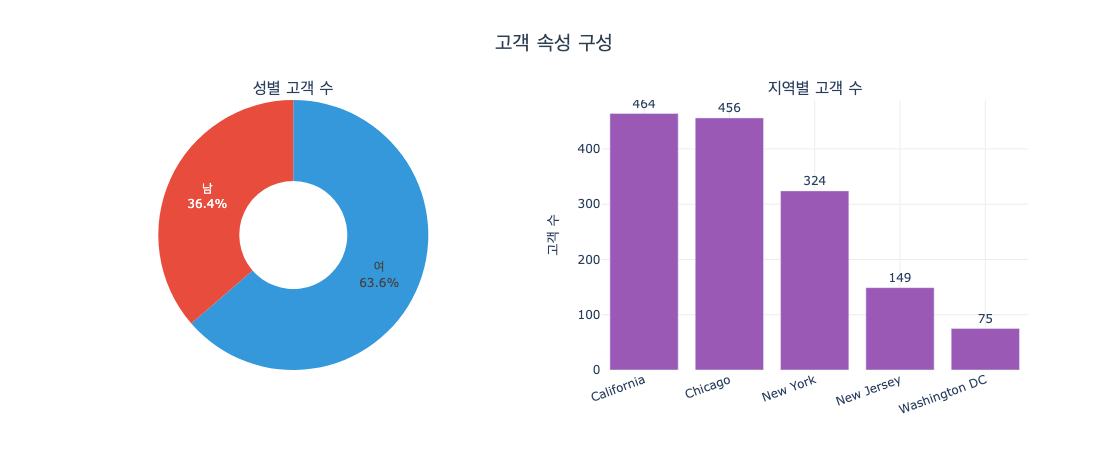

In [7]:
fig = make_subplots(rows=1,cols=2,
    specs=[[{'type':'domain'},{'type':'xy'}]],
    subplot_titles=['성별 고객 수','지역별 고객 수'])
fig.add_trace(go.Pie(labels=gender_counts.index,values=gender_counts.values,
    hole=0.4,marker=dict(colors=['#3498db','#e74c3c']),
    textinfo='label+percent',showlegend=False),row=1,col=1)
fig.add_trace(go.Bar(x=region_counts.index,y=region_counts.values,
    marker_color='#9b59b6',text=region_counts.values,textposition='outside',
    showlegend=False),row=1,col=2)
fig.update_layout(title=dict(text='고객 속성 구성',x=0.5,xanchor='center',
    font=dict(size=20,color='#2c3e50')),height=450,plot_bgcolor='white')
fig.update_xaxes(gridcolor='#ececec',tickangle=-20)
fig.update_yaxes(gridcolor='#ececec',title_text='고객 수')
fig


### 쿠폰·마케팅·고객 주문 구성


In [8]:
coupon_profile = (sales_lines
    .groupby(['쿠폰상태','할인정보제공여부','할인적용여부'],dropna=False)
    .size().reset_index(name='상품라인수'))
marketing_month = (marketing.assign(월=marketing['날짜'].dt.month)
    .groupby('월',as_index=False)[['오프라인비용','온라인비용']].sum())
order_size = pd.cut(analysis_orders['상품라인수'],
    bins=[0,1,2,np.inf],labels=['1개','2개','3개 이상'])
order_profile = order_size.value_counts().reindex(['1개','2개','3개 이상'])
payment_parts = pd.Series({
    '상품매출':analysis_orders['상품매출'].sum(),
    '배송비':analysis_orders['배송비'].sum(),
})
assert order_profile.sum()==len(analysis_orders)
assert round(payment_parts.sum(),2)==round(analysis_orders['고객결제액'].sum(),2)
assert np.isclose(sales_lines['배송비_배부액'].sum(),payment_parts['배송비'])


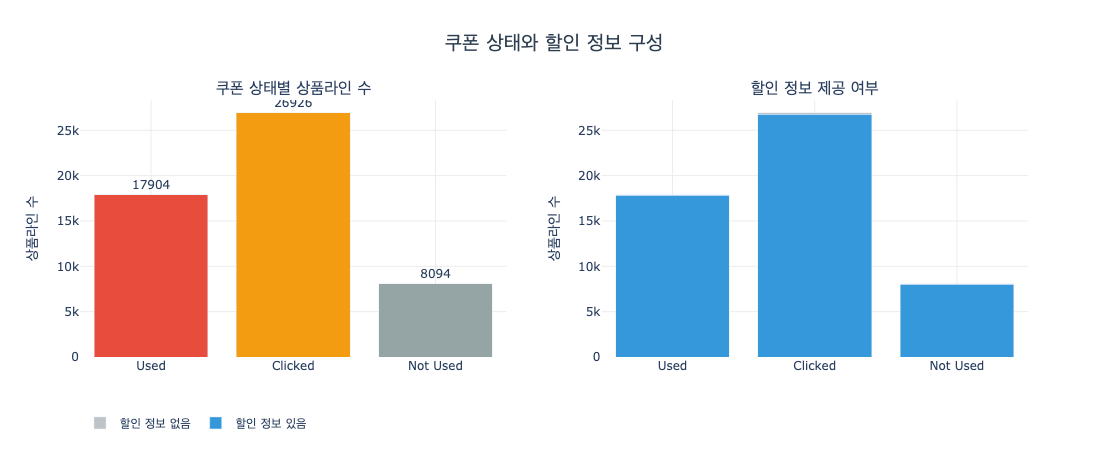

In [9]:
status_order=['Used','Clicked','Not Used']
status_counts=(sales_lines['쿠폰상태'].value_counts().reindex(status_order).fillna(0))
coverage=(sales_lines.groupby(['쿠폰상태','할인정보제공여부']).size()
    .unstack(fill_value=0).reindex(status_order).fillna(0))
fig=make_subplots(rows=1,cols=2,
    subplot_titles=['쿠폰 상태별 상품라인 수','할인 정보 제공 여부'])
colors={'Used':'#e74c3c','Clicked':'#f39c12','Not Used':'#95a5a6'}
fig.add_trace(go.Bar(x=status_order,y=status_counts.values,
    marker_color=[colors[s] for s in status_order],text=status_counts.values,
    textposition='outside',showlegend=False),row=1,col=1)
for provided,label,color in [(1,'할인 정보 있음','#3498db'),
                             (0,'할인 정보 없음','#bdc3c7')]:
    fig.add_trace(go.Bar(x=status_order,y=coverage.get(provided,pd.Series(0,index=status_order)),
        name=label,marker_color=color),row=1,col=2)
fig.update_layout(title=dict(text='쿠폰 상태와 할인 정보 구성',x=0.5,xanchor='center',
    font=dict(size=20,color='#2c3e50')),height=450,plot_bgcolor='white',
    barmode='stack',legend=dict(orientation='h',y=-0.2))
fig.update_yaxes(gridcolor='#ececec',title_text='상품라인 수')
fig.update_xaxes(gridcolor='#ececec')
fig


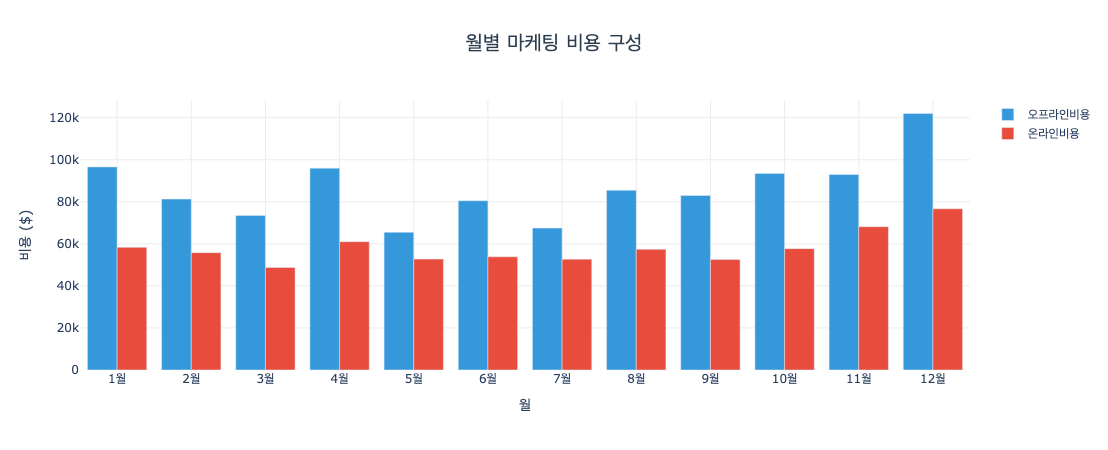

In [10]:
fig=go.Figure()
fig.add_trace(go.Bar(x=marketing_month['월'],y=marketing_month['오프라인비용'],
    name='오프라인비용',marker_color='#3498db'))
fig.add_trace(go.Bar(x=marketing_month['월'],y=marketing_month['온라인비용'],
    name='온라인비용',marker_color='#e74c3c'))
fig.update_layout(title=dict(text='월별 마케팅 비용 구성',x=0.5,xanchor='center',
    font=dict(size=20,color='#2c3e50')),height=450,plot_bgcolor='white',
    barmode='group',xaxis_title='월',yaxis_title='비용 ($)')
fig.update_xaxes(tickvals=list(range(1,13)),
    ticktext=[f'{m}월' for m in range(1,13)],gridcolor='#ececec')
fig.update_yaxes(gridcolor='#ececec')
fig


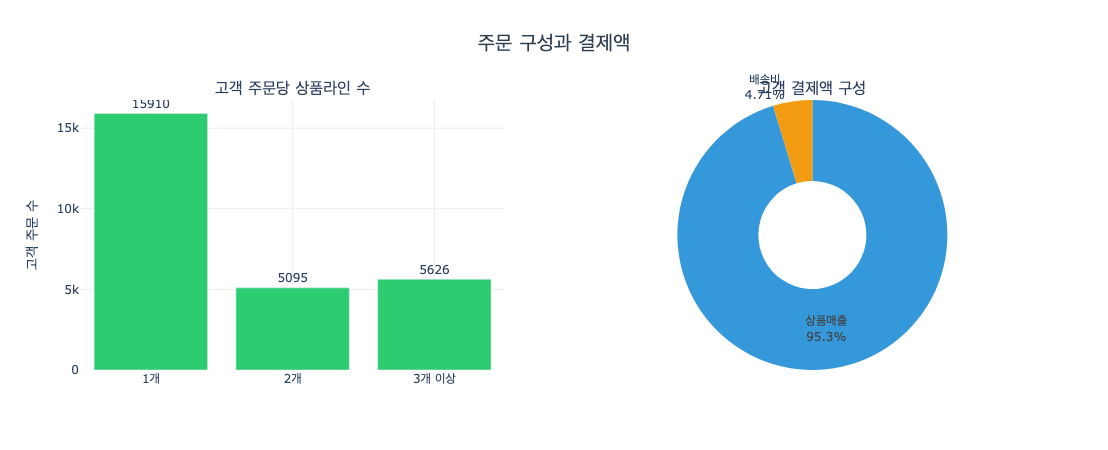

In [11]:
fig=make_subplots(rows=1,cols=2,
    specs=[[{'type':'xy'},{'type':'domain'}]],
    subplot_titles=['고객 주문당 상품라인 수','고객 결제액 구성'])
fig.add_trace(go.Bar(x=order_profile.index.astype(str),y=order_profile.values,
    marker_color='#2ecc71',text=order_profile.values,textposition='outside',
    showlegend=False),row=1,col=1)
fig.add_trace(go.Pie(labels=payment_parts.index,values=payment_parts.values,
    hole=0.4,marker=dict(colors=['#3498db','#f39c12']),
    textinfo='label+percent',showlegend=False),row=1,col=2)
fig.update_layout(title=dict(text='주문 구성과 결제액',x=0.5,xanchor='center',
    font=dict(size=20,color='#2c3e50')),height=450,plot_bgcolor='white')
fig.update_yaxes(gridcolor='#ececec',title_text='고객 주문 수')
fig.update_xaxes(gridcolor='#ececec')
fig


## 4. 월별 고객 주문과 상품매출

고객 주문과 배송비 제외 상품매출을 월별로 집계한다. 이 한 해의 월별 진폭을 반복되는 계절성으로 단정하지 않는다.


In [12]:
monthly=(analysis_orders.assign(월=analysis_orders['거래날짜'].dt.month)
    .groupby('월').agg(총매출=('상품매출','sum'),거래건수=('거래ID','size')).reset_index())
monthly['총매출']=monthly['총매출'].round(2)
assert monthly['거래건수'].sum()==26631
assert round(monthly['총매출'].sum(),2)==4840102.19
display(monthly)


,월,총매출,거래건수
0,1,434840.37,2231
1,2,325906.00,1719
2,3,354212.26,2120
3,4,435947.29,1963
4,5,324075.45,2160
5,6,323445.59,2091
6,7,403134.54,2266
7,8,414590.82,2640
8,9,355471.57,2055
9,10,434788.03,2238


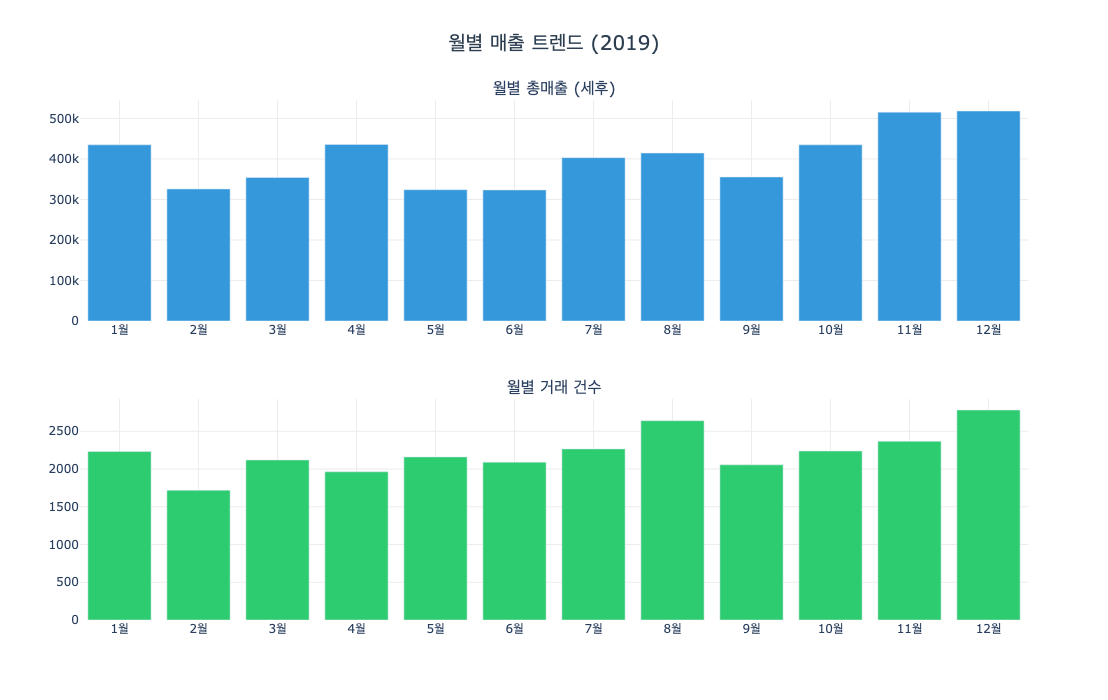

In [13]:
fig=make_subplots(
    rows=2,cols=1,subplot_titles=['월별 총매출 (세후)','월별 거래 건수'],
    vertical_spacing=0.15
)
fig.add_trace(go.Bar(x=monthly['월'],y=monthly['총매출'],
    marker_color='#3498db',name='총매출'),row=1,col=1)
fig.add_trace(go.Bar(x=monthly['월'],y=monthly['거래건수'],
    marker_color='#2ecc71',name='거래건수'),row=2,col=1)
fig.update_layout(title=dict(text='월별 매출 트렌드 (2019)',x=0.5,xanchor='center',
    font=dict(size=20,color='#2c3e50')),plot_bgcolor='white',showlegend=False,height=700)
fig.update_xaxes(tickvals=list(range(1,13)),
    ticktext=[f'{m}월' for m in range(1,13)],gridcolor='#ececec')
fig.update_yaxes(gridcolor='#ececec')
fig


## 5. 고객별 주문 빈도와 구매일 수

고객별 주문 수와 <strong>서로 다른 날 다시 구매한 횟수(<code>구매일수 - 1</code>)</strong>는 서로 다른 지표다. 같은 날 여러 고객 주문이 있어도 구매일은 하루로 센다.


In [14]:
purchase_freq=analysis_customers['Frequency']
revisit_freq=analysis_customers['구매일수']-1
distribution=pd.DataFrame({
    '고객 주문 수':purchase_freq.describe(),
    '서로 다른 날 재구매 횟수':revisit_freq.describe(),
}).round(1)
display(distribution)


,고객 주문 수,서로 다른 날 재구매 횟수
count,1468.0,1468.0
mean,18.1,1.2
std,25.0,2.2
min,1.0,0.0
25%,5.0,0.0
50%,11.0,0.5
75%,23.0,2.0
max,328.0,33.0


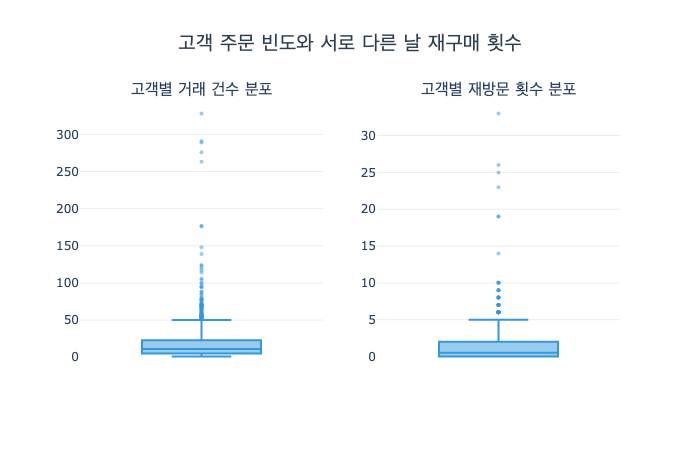

In [15]:
fig=make_subplots(rows=1,cols=2,
    subplot_titles=['고객별 거래 건수 분포','고객별 재방문 횟수 분포'])
for col,series in enumerate([purchase_freq,revisit_freq],1):
    fig.add_trace(go.Box(y=series,boxpoints='outliers',
        marker=dict(color='#3498db',size=4,opacity=0.5),
        line=dict(color='#3498db'),name='',showlegend=False),row=1,col=col)
fig.update_layout(title=dict(text='고객 주문 빈도와 서로 다른 날 재구매 횟수',
    x=0.5,xanchor='center',font=dict(size=20,color='#2c3e50')),
    height=450,plot_bgcolor='white')
fig.update_xaxes(showticklabels=False)
fig.update_yaxes(gridcolor='#ececec')
fig


고객 주문 수는 중앙값 <strong>11건</strong>, 평균 <strong>18.1건</strong>으로 오른쪽 꼬리가 길다. 구매일이 하루뿐인 고객은 <strong>734명</strong>이다. 이 차이 때문에 주문 빈도와 연간 재구매 고객 비율을 구분해 읽는다.


## 6. RFM 입력 지표와 등급

R의 원지표인 Recency(일)는 기준일(2019-12-31)부터 마지막 구매일까지의 일수, F의 원지표인 Frequency(건)는 고객 주문 수, M의 원지표인 Monetary(달러)는 배송비 제외 누적 상품매출이다. 값의 분포와 범위가 다르므로 각각 점수화한 뒤 고객 구매 행동 프로파일로 묶는다.


In [16]:
rfm=analysis_customers[['고객ID','Recency','Frequency','Monetary',
    'R','F','M','RFM_score','등급','세그먼트']].copy()
display(rfm[['Recency','Frequency','Monetary']].describe().round(2))
print(f'가중치 R/F/M: {r_w:.4f} / {f_w:.4f} / {m_w:.4f}')


,Recency,Frequency,Monetary
count,1468.00,1468.00,1468.00
mean,144.29,18.14,3297.07
std,101.94,24.98,5299.47
min,0.00,1.00,0.99
25%,55.00,5.00,673.29
50%,131.00,11.00,1796.66
75%,220.00,23.00,4078.94
max,364.00,328.00,82073.81


가중치 R/F/M: 0.2007 / 0.3392 / 0.4601


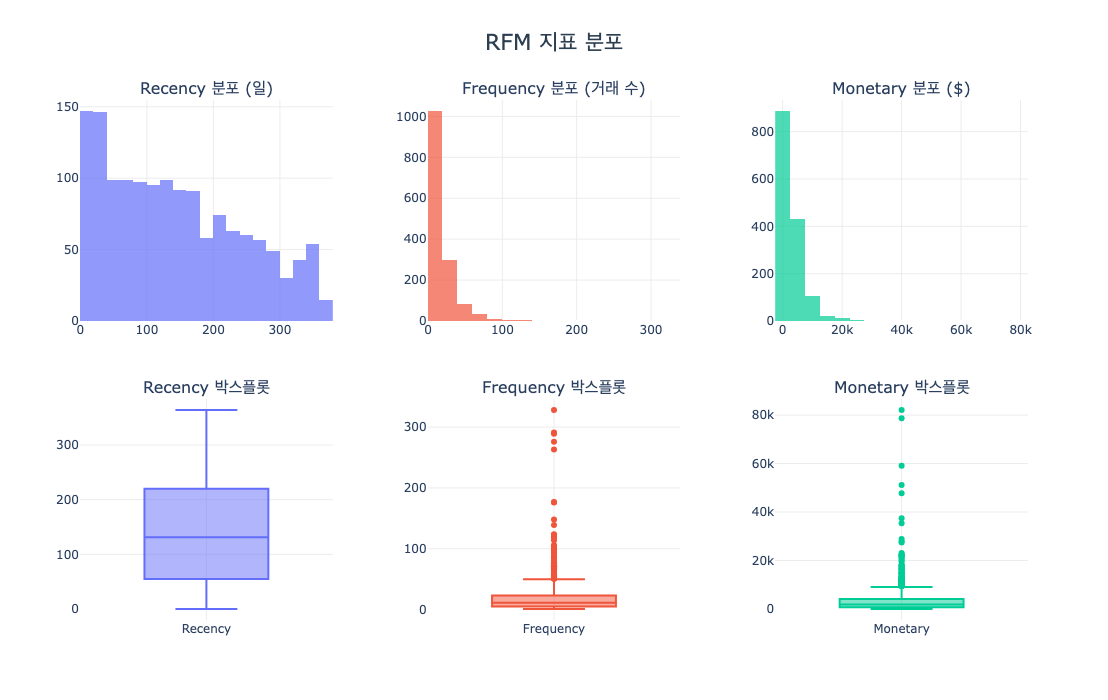

In [17]:
fig=make_subplots(rows=2,cols=3,subplot_titles=(
    'Recency 분포 (일)','Frequency 분포 (거래 수)','Monetary 분포 ($)',
    'Recency 박스플롯','Frequency 박스플롯','Monetary 박스플롯'),
    vertical_spacing=0.15,horizontal_spacing=0.1)
metrics=['Recency','Frequency','Monetary']
colors=['#636EFA','#EF553B','#00CC96']
for i,(metric,color) in enumerate(zip(metrics,colors),1):
    fig.add_trace(go.Histogram(x=rfm[metric],marker_color=color,opacity=0.7,
        name=metric,showlegend=False,nbinsx=30),row=1,col=i)
    fig.add_trace(go.Box(y=rfm[metric],marker_color=color,name=metric,
        showlegend=False,boxpoints='outliers'),row=2,col=i)
fig.update_layout(title=dict(text='RFM 지표 분포',
    font=dict(size=22,color='#2c3e50'),x=0.5,xanchor='center'),
    height=700,plot_bgcolor='white')
fig.update_xaxes(gridcolor='#ececec')
fig.update_yaxes(gridcolor='#ececec')
fig


In [18]:
grade_order=['Bronze','Silver','Gold','Platinum','Diamond']
grade_counts=rfm['등급'].value_counts().reindex(grade_order)
segment_counts=rfm['세그먼트'].value_counts()


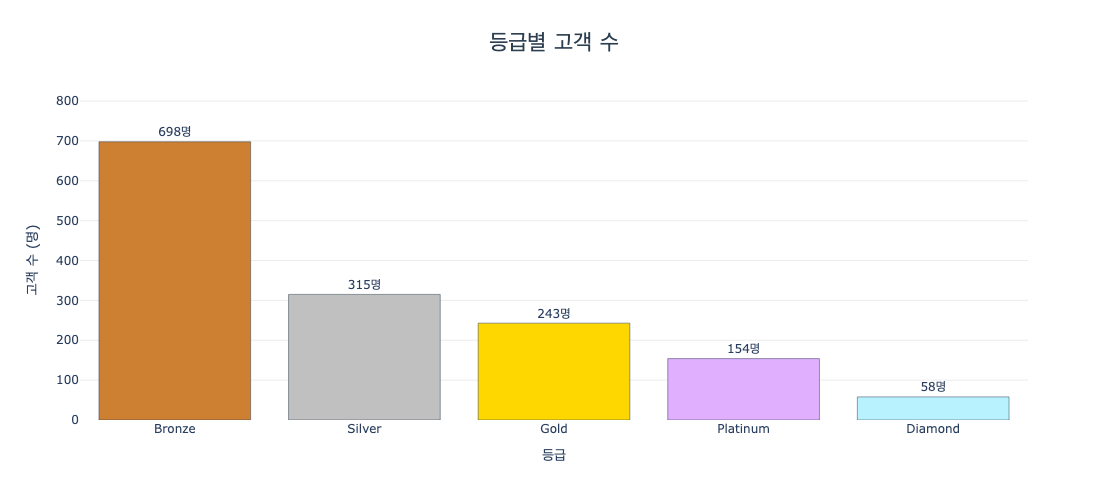

In [19]:
color_map={'Bronze':'#CD7F32','Silver':'#C0C0C0','Gold':'#FFD700',
           'Platinum':'#E0B0FF','Diamond':'#B9F2FF'}
fig=go.Figure(go.Bar(
    x=grade_counts.index,y=grade_counts.values,
    marker=dict(color=[color_map[g] for g in grade_counts.index],
                line=dict(color='#2c3e50',width=0.5)),
    text=[f'{n:,}명' for n in grade_counts.values],textposition='outside'
))
fig.update_layout(title=dict(text='등급별 고객 수',
    font=dict(size=22,color='#2c3e50'),x=0.5,xanchor='center'),
    height=500,plot_bgcolor='white',
    yaxis=dict(range=[0,grade_counts.max()*1.15],gridcolor='#ececec'),
    xaxis_title='등급',yaxis_title='고객 수 (명)')
fig


### 세그먼트별 고객 수와 비율


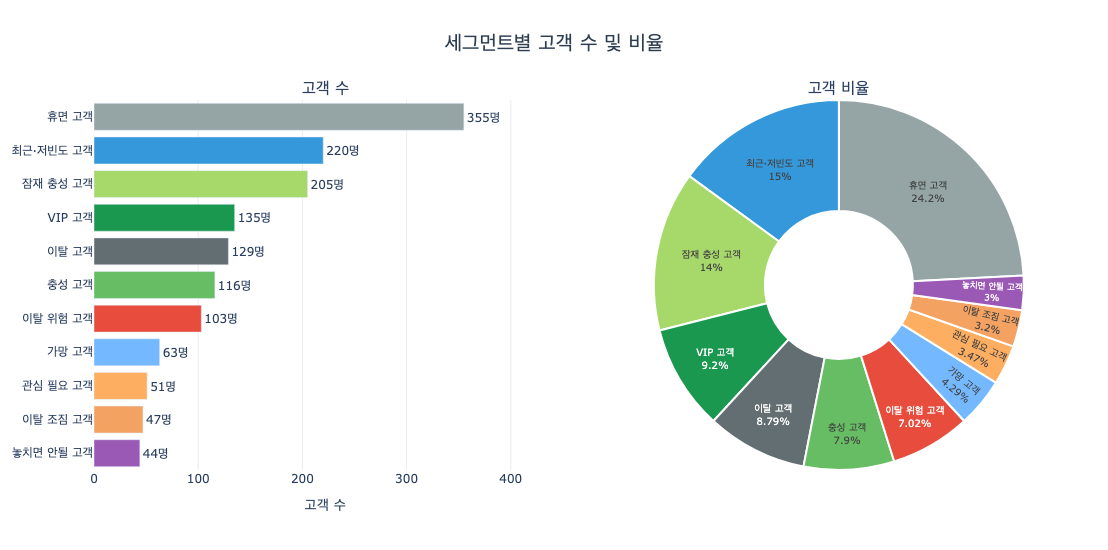

In [20]:
seg_dist=segment_counts.rename_axis('세그먼트').reset_index(name='고객수')
seg_color_map = {
    'VIP 고객': '#1a9850',
    '충성 고객': '#66bd63',
    '잠재 충성 고객': '#a6d96a',
    '최근·저빈도 고객': '#3498db',
    '가망 고객': '#74b9ff',
    '관심 필요 고객': '#fdae61',
    '이탈 조짐 고객': '#f4a261',
    '놓치면 안될 고객': '#9b59b6',
    '이탈 위험 고객': '#e74c3c',
    '휴면 고객': '#95a5a6',
    '이탈 고객': '#636e72',
    'Others': '#dfe6e9',
}

seg_sorted = seg_dist.sort_values('고객수', ascending=True)
seg_colors_sorted = [seg_color_map.get(s, '#dfe6e9') for s in seg_sorted['세그먼트']]

fig = make_subplots(
    rows=1, cols=2,
    specs=[[{'type': 'xy'}, {'type': 'pie'}]],
    column_widths=[0.55, 0.45],
    subplot_titles=['고객 수', '고객 비율']
)

fig.add_trace(
    go.Bar(
        x=seg_sorted['고객수'],
        y=seg_sorted['세그먼트'],
        orientation='h',
        marker_color=seg_colors_sorted,
        text=seg_sorted['고객수'].apply(lambda x: f'{x:,}명'),
        textposition='outside',
        showlegend=False
    ),
    row=1, col=1
)

fig.add_trace(
    go.Pie(
        labels=seg_dist['세그먼트'],
        values=seg_dist['고객수'],
        marker=dict(
            colors=[seg_color_map.get(s, '#dfe6e9') for s in seg_dist['세그먼트']],
            line=dict(color='white', width=2)
        ),
        textinfo='label+percent',
        textposition='inside',
        textfont=dict(size=10),
        hole=0.4,
        sort=False,
        showlegend=False
    ),
    row=1, col=2
)

fig.update_layout(
    title=dict(
        text='세그먼트별 고객 수 및 비율',
        font=dict(size=20, color='#2c3e50'), x=0.5, xanchor='center'
    ),
    xaxis=dict(range=[0, seg_sorted['고객수'].max() * 1.25], gridcolor='#ececec', title='고객 수'),
    plot_bgcolor='white',
    height=550
)
fig


### 등급·세그먼트의 RFM 분포

R 점수(최근성, 1–5점)·F 점수(구매빈도, 1–5점) 구간 안의 위치를 원지표로 펼치고 겹침을 줄이기 위해 작은 흔들림을 더했다. 점 크기는 Monetary를 나타내며 상위 5%에서 크기를 제한했다. 축의 세부 위치는 시각화용이며 분류 기준은 R·F·M 점수다.


In [21]:
rfm_plot = rfm.copy()

# Bin-interpolation scaling (RFM_scale 패턴)
r_intervals = pd.qcut(rfm_plot['Recency'], q=[0, 0.2, 0.4, 0.6, 0.8, 1.0])
r_left = r_intervals.apply(lambda x: x.left).astype(float).clip(lower=0)
r_right = r_intervals.apply(lambda x: x.right).astype(float)
rfm_plot['R_scale'] = (rfm_plot['R'] - 1) + (rfm_plot['Recency'] - r_left - 0.01) / (r_right - r_left) - 0.0001

f_q1 = rfm_plot['Frequency'].quantile(0.25)
f_q2 = rfm_plot['Frequency'].quantile(0.50)
f_q3 = rfm_plot['Frequency'].quantile(0.75)
f_upper = f_q3 + 1.5 * (f_q3 - f_q1)
f_intervals = pd.cut(rfm_plot['Frequency'], bins=[0, f_q1, f_q2, f_q3, f_upper, rfm_plot['Frequency'].max()])
f_left = f_intervals.apply(lambda x: x.left).astype(float)
f_right = f_intervals.apply(lambda x: x.right).astype(float)
rfm_plot['F_scale'] = (rfm_plot['F'] - 1) + (rfm_plot['Frequency'] - f_left - 0.01) / (f_right - f_left) - 0.0001

np.random.seed(42)
rfm_plot['R_scale'] += np.random.uniform(-0.1, 0.1, len(rfm_plot))
rfm_plot['F_scale'] += np.random.uniform(-0.1, 0.1, len(rfm_plot))

m_min = rfm_plot['Monetary'].min()
m_cap = rfm_plot['Monetary'].quantile(0.95)
rfm_plot['marker_size'] = (
    (rfm_plot['Monetary'].clip(upper=m_cap) - m_min) / (m_cap - m_min) * 16 + 4
).round(0)

segment_colors = {
    'VIP 고객': '#1a9850',
    '충성 고객': '#66bd63',
    '잠재 충성 고객': '#a6d96a',
    '최근·저빈도 고객': '#3498db',
    '가망 고객': '#74b9ff',
    '관심 필요 고객': '#fdae61',
    '이탈 조짐 고객': '#f4a261',
    '놓치면 안될 고객': '#9b59b6',
    '이탈 위험 고객': '#e74c3c',
    '휴면 고객': '#95a5a6',
    '이탈 고객': '#636e72',
    'Others': '#dfe6e9',
}
grade_color_map = {
    'Diamond': '#B9F2FF',
    'Platinum': '#E0B0FF',
    'Gold': '#FFD700',
    'Silver': '#C0C0C0',
    'Bronze': '#CD7F32',
}


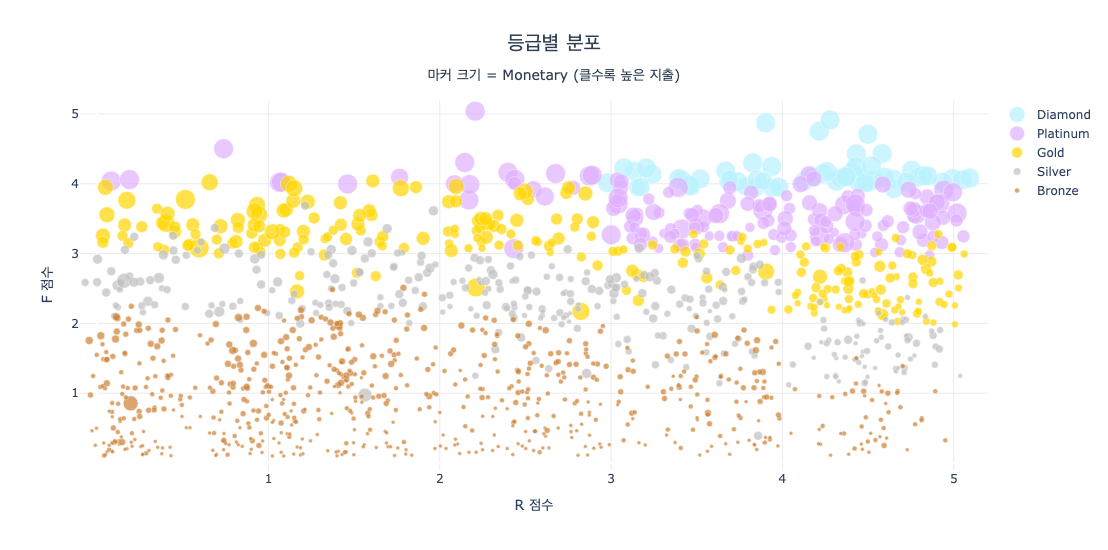

In [22]:
# 등급별 분포
fig = go.Figure()
for grade in ['Diamond', 'Platinum', 'Gold', 'Silver', 'Bronze']:
    sub = rfm_plot[rfm_plot['등급'] == grade]
    fig.add_trace(go.Scatter(
        x=sub['R_scale'],
        y=sub['F_scale'],
        mode='markers',
        marker=dict(color=grade_color_map[grade], size=sub['marker_size'], opacity=0.7,
                    line=dict(width=0.5, color='white')),
        name=grade,
        hovertemplate=(
            f'등급: {grade}<br>'
            'R: %{customdata[0]} | F: %{customdata[1]}<br>'
            'Monetary: $%{customdata[2]:,.0f}<extra></extra>'
        ),
        customdata=sub[['R', 'F', 'Monetary']].values
    ))

fig.update_layout(
    title=dict(
        text='등급별 분포<br><sub>마커 크기 = Monetary (클수록 높은 지출)</sub>',
        font=dict(size=20, color='#2c3e50'), x=0.5, xanchor='center'
    ),
    xaxis=dict(tickvals=[1, 2, 3, 4, 5], range=[-0.1, 5.2], gridcolor='#ececec', title_text='R 점수'),
    yaxis=dict(tickvals=[1, 2, 3, 4, 5], range=[-0.1, 5.2], gridcolor='#ececec', title_text='F 점수'),
    plot_bgcolor='white',
    width=700,
    height=550,
    legend=dict(orientation='v', x=1.01, y=1)
)
fig


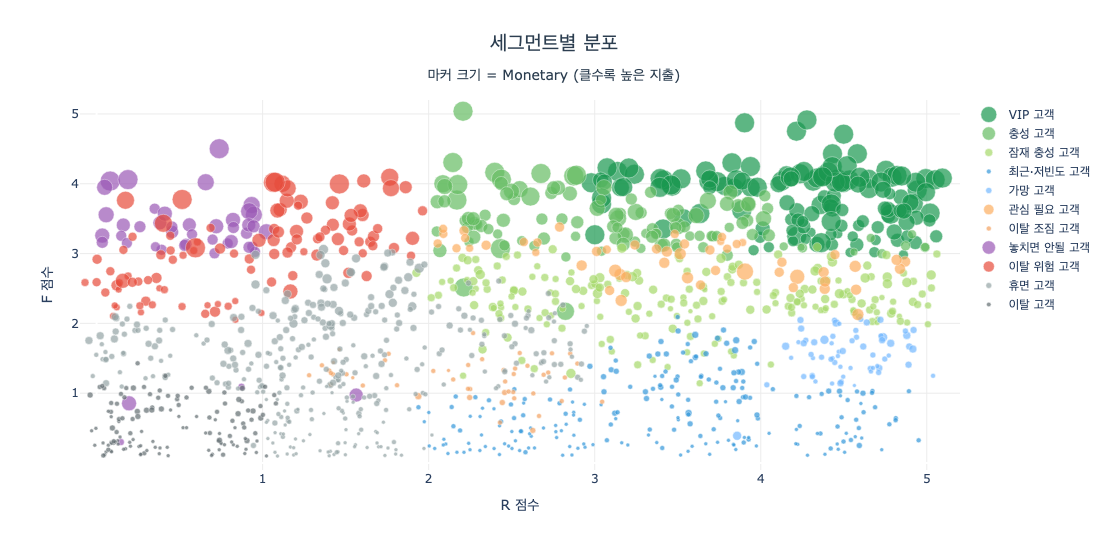

In [23]:
# 세그먼트별 분포
fig = go.Figure()
for segment, color in segment_colors.items():
    sub = rfm_plot[rfm_plot['세그먼트'] == segment]
    if len(sub) == 0:
        continue
    fig.add_trace(go.Scatter(
        x=sub['R_scale'],
        y=sub['F_scale'],
        mode='markers',
        marker=dict(color=color, size=sub['marker_size'], opacity=0.7,
                    line=dict(width=0.5, color='white')),
        name=segment,
        hovertemplate=(
            '등급: %{customdata[0]}<br>'
            f'세그먼트: {segment}<br>'
            'R: %{customdata[1]} | F: %{customdata[2]}<br>'
            'Monetary: $%{customdata[3]:,.0f}<extra></extra>'
        ),
        customdata=sub[['등급', 'R', 'F', 'Monetary']].values
    ))

fig.update_layout(
    title=dict(
        text='세그먼트별 분포<br><sub>마커 크기 = Monetary (클수록 높은 지출)</sub>',
        font=dict(size=20, color='#2c3e50'), x=0.5, xanchor='center'
    ),
    xaxis=dict(tickvals=[1, 2, 3, 4, 5], range=[-0.1, 5.2], gridcolor='#ececec', title_text='R 점수'),
    yaxis=dict(tickvals=[1, 2, 3, 4, 5], range=[-0.1, 5.2], gridcolor='#ececec', title_text='F 점수'),
    plot_bgcolor='white',
    width=700,
    height=550,
    legend=dict(orientation='v', x=1.01, y=1)
)
fig


등급과 행동 상태는 같은 RFM 입력에서 만든 <strong>관찰기간 프로파일</strong>이다. 등급 분포 자체가 미래 매출이나 이탈 예측 성능을 증명하지는 않는다.
